In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path 
import sys,importlib
import re,ast
import joblib,openpyxl,inspect
import json , shutil
import importlib.metadata as metadata

In [2]:
folders = ["src", "notebooks", "models", "reports", "data"]

In [29]:
for notebook_file in ["03_baseline.ipynb","13_beat_baseline_attrV2model.ipynb"]:
    path = Path(notebook_file)
    print(f"\n{'='*65}")
    print("NOTEBOOK:", notebook_file)
    if not path.exists():
        print("NOT FOUND")
        continue
    with open(path, encoding="utf-8") as f:
        nb = json.load(f)
    print("Total cells:", len(nb["cells"]))
    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))
        if cell["cell_type"] == "code" and source.strip():
            print(f"\n--- CELL {i} ---")
            print(source[:2500])
        elif cell["cell_type"] == "markdown" and source.strip():
            print(f"\n--- MARKDOWN {i} ---")
            print(source[:500])


NOTEBOOK: 03_baseline.ipynb
Total cells: 33

--- CELL 0 ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys


--- CELL 1 ---
from pathlib import Path

project_path = Path("/workspace")

skip_dirs = {
    ".Trash-0",
    ".ipynb_checkpoints",
    "__pycache__",
    ".git"
}

for path in sorted(project_path.rglob("*")):
    if not path.is_file():
        continue

    if any(part in skip_dirs for part in path.relative_to(project_path).parts):
        continue

    name = path.name.lower()

    if any(term in name for term in [
        "baseline",
        "benchmark",
        "features.py",
        "feature.py"
    ]):
        print(path)

--- CELL 2 ---
from pathlib import Path
import ast

feature_file = Path("/workspace/src/features.py")

source_code = feature_file.read_text(encoding="utf-8")
tree = ast.parse(source_code)

print("=== FUNCTIONS AND CLASSES ===")

for node in tree.body:
    if isinstance(node, (ast.FunctionDef, ast.

In [25]:
excel_path = "data/raw/02_CortexHR_AI_ML_Dataset.xlsx"
wb = openpyxl.load_workbook(excel_path, read_only=True, data_only=True)
ws = wb["baseline_benchmarks"]

In [26]:
for row in ws.iter_rows(values_only=True):
    print(row)

('model', 'roc_auc_mean', 'roc_auc_sd', 'pr_auc_mean', 'precision_mean', 'recall_mean', 'f1_mean', 'accuracy_mean', 'comment')
('Dummy (always stays)', 0.5, 0, 0.146, 0, 0, 0, 0.854, 'Looks 85% accurate yet catches nobody: why accuracy alone misleads')
('Logistic Regression (class_weight=balanced)', 0.713, 0.01, 0.332, 0.26, 0.63, 0.368, 0.683, 'Clean features only (reference target)')
('Decision Tree (depth 4, balanced)', 0.65, 0.019, 0.256, 0.234, 0.524, 0.322, 0.676, 'Clean features only (reference target)')
('Random Forest (300 trees, balanced)', 0.715, 0.018, 0.336, 0.523, 0.089, 0.151, 0.854, 'Clean features only (reference target)')
('LEAKY Logistic Regression (adds exit information)', 1, 0, 1, 1, 1, 1, 1, 'Too good to be true: this is data leakage')


In [27]:
df = pd.read_csv("data/processed/attrition_features.csv")
print("\n" + "="*65)
print("PROCESSED ATTRITION DATA")
print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes.to_string())


PROCESSED ATTRITION DATA
Shape: (2389, 72)
Columns:
['row_id', 'employee_id', 'observation_date', 'department_id', 'role_id', 'job_level', 'work_location', 'work_mode', 'employment_type', 'highest_education', 'tenure_months', 'total_experience_years', 'previous_employers_count', 'commute_distance_km', 'annual_fixed_pay', 'comp_ratio', 'raises_received', 'last_raise_pct', 'months_since_last_raise', 'promotions_received', 'months_since_last_promotion', 'internal_transfers', 'last_performance_rating', 'last_engagement_score', 'manager_changes_12m', 'training_hours_12m', 'attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'avg_hours_worked_3m', 'wfh_share_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m', 'dept_attrition_rate_prior_12m', 'left_within_12m', 'voluntary_left_within_12m', 'source', 'exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount', 'attendance_scheduled_days', 'attendance_present_days', 'attendance_wfh_days

In [35]:
sys.path.insert(0, "/workspace/src")
from features import build_pipeline
print("=" * 60)
print("ORIGINAL PREPROCESSING PIPELINE")
print("=" * 60)
print(inspect.getsource(build_pipeline))

ORIGINAL PREPROCESSING PIPELINE
def build_pipeline(numeric_columns, categorical_columns):
    """
    Build reusable preprocessing for numeric and categorical features.
    The target column must not be included in either column list.
    """
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns),
    ], remainder="drop")
    return Pipeline([
    ("preprocessor", preprocessor)
])



In [36]:

# 2. Check installed gradient boosting libraries
print("\n" + "=" * 60)
print("BOOSTING LIBRARY AVAILABILITY")
print("=" * 60)

for package in ["xgboost", "lightgbm", "scikit-learn"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")


BOOSTING LIBRARY AVAILABILITY
xgboost: 3.4.1
lightgbm: NOT INSTALLED
scikit-learn: 1.9.1


In [37]:
notebook_path = Path("/workspace/03_baseline.ipynb")
with open(notebook_path, encoding="utf-8") as f:
    baseline_nb = json.load(f)

In [38]:
for i, cell in enumerate(baseline_nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(term in source for term in [
        "results_df.round",
        "Cross-validation folds"
    ]):
        print(f"\nCELL {i}")

        for output in cell.get("outputs", []):
            if "text" in output:
                print("".join(output["text"]))

            for mime in ["text/plain"]:
                data = output.get("data", {})
                if mime in data:
                    print(data[mime])


CELL 27
['                     roc_auc  pr_auc  precision  recall    f1  accuracy\n', 'model                                                                  \n', 'Dummy                  0.500   0.146      0.000   0.000  0.00     0.854\n', 'Logistic Regression    0.702   0.293      0.258   0.596  0.36     0.691']

CELL 28
Cross-validation folds: 5
Random state: 42
Feature count: 61
All rows have out-of-fold probabilities: True



In [39]:
# reason to use XGboost
'''
It directly satisfies the Task 13 gradient-boosting requirement.
It supports class imbalance through scale_pos_weight.
It supports probability predictions, which we need for calibration.
We can preserve our existing preprocessing pipeline.
'''

'\nIt directly satisfies the Task 13 gradient-boosting requirement.\nIt supports class imbalance through scale_pos_weight.\nIt supports probability predictions, which we need for calibration.\nWe can preserve our existing preprocessing pipeline.\n'

In [17]:
from sklearn.model_selection import StratifiedKFold
from features import build_pipeline
df_model = pd.read_csv("/workspace/data/processed/attrition_features.csv")
target = "left_within_12m"
excluded_columns = [
    "row_id",
    "employee_id",
    "observation_date",
    "source",
    "voluntary_left_within_12m",
    "exit_date",
    "resignation_date",
    "exit_reason",
    "exit_interview_done",
    "fnf_settlement_amount"
]


# Validation checks






print("\nPipeline and original experiment reconstructed successfully.")

DATA: (2389, 61)
TARGET DISTRIBUTION:
left_within_12m
0    2040
1     349
Name: count, dtype: int64

FEATURES
Numeric: 55
Categorical: 6

CROSS-VALIDATION
Outer folds: 5
Random state: 42
Fold 1: Train=1911, Validation=478, Train positives=279, Validation positives=70
Fold 2: Train=1911, Validation=478, Train positives=279, Validation positives=70
Fold 3: Train=1911, Validation=478, Train positives=279, Validation positives=70
Fold 4: Train=1911, Validation=478, Train positives=279, Validation positives=70
Fold 5: Train=1912, Validation=477, Train positives=280, Validation positives=69

Pipeline and original experiment reconstructed successfully.


In [ ]:
X = df_model.drop(columns=excluded_columns + [target],errors="ignore")
y = df_model[target].astype(int)

In [40]:
numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(include=["object", "category", "string", "bool", "boolean"]).columns.tolist()

In [41]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [42]:
folds = list(cv.split(X, y))

In [43]:
assert X.shape == (2389, 61), f"Unexpected shape: {X.shape}"
assert y.nunique() == 2
assert not y.isna().any()
assert set(numeric_columns + categorical_columns) == set(X.columns)

In [44]:
print("DATA:", X.shape)
print("TARGET DISTRIBUTION:")
print(y.value_counts())

print("\nFEATURES")
print("Numeric:", len(numeric_columns))
print("Categorical:", len(categorical_columns))

print("\nCROSS-VALIDATION")
print("Outer folds:", len(folds))
print("Random state: 42")

DATA: (2389, 61)
TARGET DISTRIBUTION:
left_within_12m
0    2040
1     349
Name: count, dtype: int64

FEATURES
Numeric: 55
Categorical: 6

CROSS-VALIDATION
Outer folds: 5
Random state: 42


In [45]:
for i, (train_idx, valid_idx) in enumerate(folds, 1):
    print(
        f"Fold {i}: Train={len(train_idx)}, "
        f"Validation={len(valid_idx)}, "
        f"Train positives={y.iloc[train_idx].sum()}, "
        f"Validation positives={y.iloc[valid_idx].sum()}")

Fold 1: Train=1911, Validation=478, Train positives=279, Validation positives=70
Fold 2: Train=1911, Validation=478, Train positives=279, Validation positives=70
Fold 3: Train=1911, Validation=478, Train positives=279, Validation positives=70
Fold 4: Train=1911, Validation=478, Train positives=279, Validation positives=70
Fold 5: Train=1912, Validation=477, Train positives=280, Validation positives=69


In [46]:
from sklearn.model_selection import (cross_val_predict,GridSearchCV,StratifiedKFold)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
from xgboost import XGBClassifier
from features import build_pipeline
v1_model = Pipeline([("preprocessing", build_pipeline(numeric_columns,categorical_columns)),
    ("classifier", LogisticRegression(class_weight="balanced",max_iter=1000,random_state=42))])
v1_oof = cross_val_predict(v1_model,X,y,cv=folds,method="predict_proba",n_jobs=1)[:, 1]
print("V1 out-of-fold predictions:", len(v1_oof))

V1 out-of-fold predictions: 2389


In [49]:
param_grid = {
    "classifier__max_depth": [2, 3],
    "classifier__learning_rate": [0.03, 0.08],
    "classifier__n_estimators": [200, 400]
}

# Store predictions and tuning results
v2_oof = np.zeros(len(y), dtype=float)
tuning_logs = []
fold_summaries = []

In [51]:
for fold_number, (train_idx, valid_idx) in enumerate(folds, 1):
    print(f"\nStarting outer fold {fold_number}/5")
    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]
    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]
    negative_count = int((y_train == 0).sum())
    positive_count = int((y_train == 1).sum())
    scale_pos_weight = negative_count / positive_count
    xgb = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        random_state=42,
        n_jobs=1
    )
    v2_pipeline = Pipeline([
        ("preprocessing", build_pipeline(
            numeric_columns,
            categorical_columns
        )),
        ("classifier", xgb)
    ])
    inner_cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
    search = GridSearchCV(
        estimator=v2_pipeline,
        param_grid=param_grid,
        scoring="average_precision",
        cv=inner_cv,
        n_jobs=1,
        refit=True,
        return_train_score=True
    )
    search.fit(X_train, y_train)
    fold_log = pd.DataFrame(search.cv_results_)
    for _, result in fold_log.iterrows():
        tuning_logs.append({
            "outer_fold": fold_number,
            "params": result["params"],
            "inner_mean_pr_auc": result["mean_test_score"],
            "inner_std_pr_auc": result["std_test_score"],
            "inner_train_pr_auc": result["mean_train_score"],
            "rank": result["rank_test_score"]
        })
    best_model = search.best_estimator_
    probabilities = best_model.predict_proba(X_valid)[:, 1]

    v2_oof[valid_idx] = probabilities

    fold_summaries.append({
        "outer_fold": fold_number,
        "best_params": search.best_params_,
        "best_inner_pr_auc": search.best_score_,
        "outer_valid_pr_auc": average_precision_score(
            y_valid, probabilities
        ),
        "outer_valid_roc_auc": roc_auc_score(
            y_valid, probabilities
        ), "scale_pos_weight": scale_pos_weight
    })
    print("Best parameters:", search.best_params_)
    print("Best inner PR-AUC:", round(search.best_score_, 4))
    print("Outer validation PR-AUC:",
          round(average_precision_score(y_valid, probabilities), 4))




Starting outer fold 1/5
Best parameters: {'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}
Best inner PR-AUC: 0.3372
Outer validation PR-AUC: 0.2995

Starting outer fold 2/5
Best parameters: {'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__n_estimators': 400}
Best inner PR-AUC: 0.3561
Outer validation PR-AUC: 0.3342

Starting outer fold 3/5
Best parameters: {'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}
Best inner PR-AUC: 0.3235
Outer validation PR-AUC: 0.3611

Starting outer fold 4/5
Best parameters: {'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}
Best inner PR-AUC: 0.3063
Outer validation PR-AUC: 0.4396

Starting outer fold 5/5
Best parameters: {'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}
Best inner PR-AUC: 0.3232
Outer validation PR-AUC: 0.3858


In [52]:
# 4. EVALUATE BOTH MODELS
def calculate_metrics(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Accuracy": accuracy_score(y_true, predictions)
    }
comparison_v1_v2 = pd.DataFrame({
    "Logistic Regression V1": calculate_metrics(y, v1_oof),
    "XGBoost V2": calculate_metrics(y, v2_oof)
})
tuning_log_df = pd.DataFrame(tuning_logs)
fold_summary_df = pd.DataFrame(fold_summaries)

In [53]:
print("\n" + "=" * 65)
print("V1 VS V2 OUT-OF-FOLD COMPARISON")
print("=" * 65)
print(comparison_v1_v2.round(4))
print("\n" + "=" * 65)
print("FOLD-WISE BEST PARAMETERS")
print("=" * 65)
print(fold_summary_df.to_string(index=False))
print("\n" + "=" * 65)
print("COMPLETE HYPERPARAMETER TUNING LOG")
print("=" * 65)
print(
    tuning_log_df.sort_values(["outer_fold", "rank"]).to_string(index=False))


V1 VS V2 OUT-OF-FOLD COMPARISON
           Logistic Regression V1  XGBoost V2
ROC-AUC                    0.7018      0.7223
PR-AUC                     0.2932      0.3471
Precision                  0.2581      0.2765
Recall                     0.5960      0.5673
F1                         0.3602      0.3718
Accuracy                   0.6907      0.7200

FOLD-WISE BEST PARAMETERS
 outer_fold                                                                                      best_params  best_inner_pr_auc  outer_valid_pr_auc  outer_valid_roc_auc  scale_pos_weight
          1 {'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}           0.337247            0.299547             0.691457          5.849462
          2 {'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__n_estimators': 400}           0.356053            0.334219             0.701120          5.849462
          3 {'classifier__learning_rate': 0.03, 'classifi

In [ ]:
# 1. CALIBRATION METRICS

In [57]:
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
def calculate_calibration_metrics(y_true, probabilities, n_bins=10):
    probabilities = np.asarray(probabilities)
    y_true = np.asarray(y_true)
    clipped = np.clip(probabilities, 1e-15, 1 - 1e-15)
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(
        probabilities, bin_edges[1:-1]
    )
    ece = 0.0
    for bin_number in range(n_bins):
        mask = bin_ids == bin_number
        if mask.sum() == 0:
            continue
        observed_rate = y_true[mask].mean()
        predicted_rate = probabilities[mask].mean()
        ece += (
            mask.sum() / len(y_true)
        ) * abs(observed_rate - predicted_rate)
    return {
        "Brier Score": brier_score_loss(y_true, probabilities),
        "Log Loss": log_loss(y_true, clipped),
        "ECE": ece
    }

In [58]:
# 2. COMPARE V1 AND V2
calibration_results = pd.DataFrame({
    "Logistic Regression V1":
        calculate_calibration_metrics(y, v1_oof),

    "XGBoost V2":
        calculate_calibration_metrics(y, v2_oof)
})

print("CALIBRATION METRICS")
print(calibration_results.round(4))

CALIBRATION METRICS
             Logistic Regression V1  XGBoost V2
Brier Score                  0.2063      0.1917
Log Loss                     0.6108      0.5675
ECE                          0.2493      0.2727


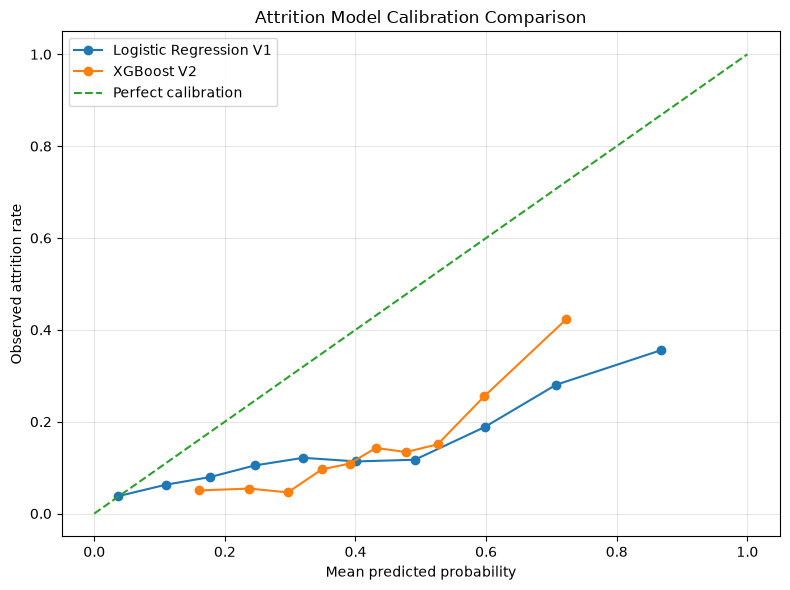

In [59]:
plt.figure(figsize=(8, 6))
for model_name, probabilities in [("Logistic Regression V1", v1_oof),("XGBoost V2", v2_oof)]:
    fraction_positive, mean_predicted = calibration_curve(y,probabilities,n_bins=10,strategy="quantile")
    plt.plot(mean_predicted,fraction_positive,marker="o",label=model_name)
plt.plot([0, 1],[0, 1],linestyle="--",label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed attrition rate")
plt.title("Attrition Model Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
from sklearn.calibration import ( CalibratedClassifierCV,calibration_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)
from xgboost import XGBClassifier
from features import build_pipeline
v2_sigmoid_oof = np.zeros(len(y), dtype=float)
for fold_number, (train_idx, valid_idx) in enumerate(folds, 1):
    print(f"Calibrating outer fold {fold_number}/5")
    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]
    y_train = y.iloc[train_idx]
    best_params = fold_summary_df.loc[
        fold_number - 1, "best_params"
    ]
    best_params = {
        key.replace("classifier__", ""): value
        for key, value in best_params.items()
    }
    scale_pos_weight = (
        (y_train == 0).sum() / (y_train == 1).sum()
    )
    xgb = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        random_state=42,
        n_jobs=1,
        **best_params
    )
    base_pipeline = Pipeline([ ("preprocessing", build_pipeline(numeric_columns,categorical_columns)),
        ("classifier", xgb)])
    calibration_cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
    calibrated_model = CalibratedClassifierCV(estimator=base_pipeline,method="sigmoid",cv=calibration_cv,ensemble=False)
    calibrated_model.fit(X_train, y_train)
    v2_sigmoid_oof[valid_idx] = (
        calibrated_model.predict_proba(X_valid)[:, 1]
    )

Calibrating outer fold 1/5
Calibrating outer fold 2/5
Calibrating outer fold 3/5
Calibrating outer fold 4/5
Calibrating outer fold 5/5


In [61]:
# 2. CONSISTENT CALIBRATION METRICS
def calibration_metrics(y_true, probabilities, n_bins=10):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(
        probabilities,
        bin_edges[1:-1]
    )
    ece = 0.0
    for bin_number in range(n_bins):
        mask = bin_ids == bin_number
        if mask.sum() == 0:
            continue
        predicted = probabilities[mask].mean()
        observed = y_true[mask].mean()
        ece += (
            mask.sum() / len(y_true)
        ) * abs(predicted - observed)
    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Brier Score": brier_score_loss(y_true, probabilities),
        "Log Loss": log_loss(
            y_true,
            np.clip(probabilities, 1e-15, 1 - 1e-15)
        ),
        "ECE": ece
    }
calibration_comparison = pd.DataFrame({
    "V1 Raw": calibration_metrics(y, v1_oof),
    "V2 Raw": calibration_metrics(y, v2_oof),
    "V2 Sigmoid": calibration_metrics(y, v2_sigmoid_oof)
})
print("\nCALIBRATION COMPARISON")
print(calibration_comparison.round(4))


CALIBRATION COMPARISON
             V1 Raw  V2 Raw  V2 Sigmoid
ROC-AUC      0.7018  0.7223      0.7230
PR-AUC       0.2932  0.3471      0.3521
Brier Score  0.2063  0.1917      0.1120
Log Loss     0.6108  0.5675      0.3723
ECE          0.2493  0.2727      0.0150


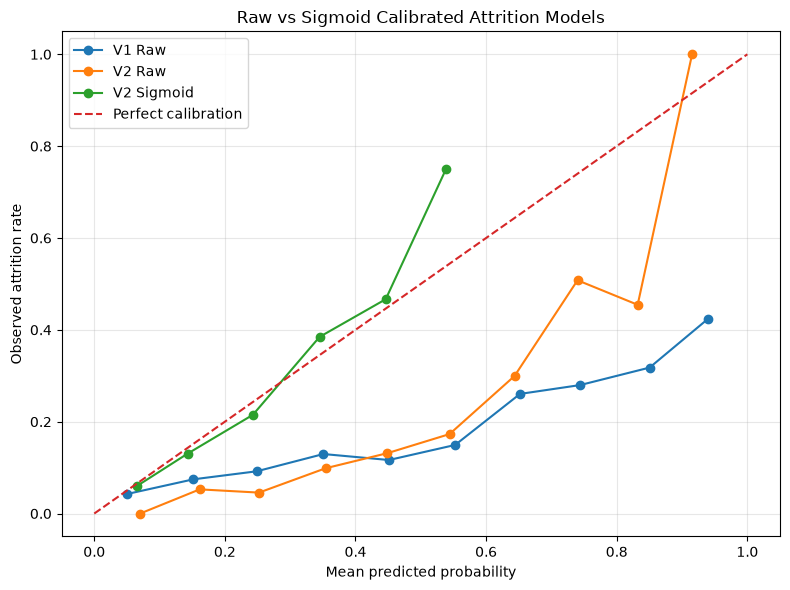

In [62]:
# 3. RELIABILITY DIAGRAM
plt.figure(figsize=(8, 6))
for name, probabilities in [
    ("V1 Raw", v1_oof),
    ("V2 Raw", v2_oof),
    ("V2 Sigmoid", v2_sigmoid_oof)
]:
    observed, predicted = calibration_curve(
        y,
        probabilities,
        n_bins=10,
        strategy="uniform"
    )
    plt.plot(
        predicted,
        observed,
        marker="o",
        label=name
    )
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed attrition rate")
plt.title("Raw vs Sigmoid Calibrated Attrition Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    precision_score,
    recall_score,
    f1_score
)
# 1. CALIBRATION BIN AUDIT
def calibration_bin_audit(y_true, probabilities, model_name):
    edges = np.linspace(0, 1, 11)
    bin_ids = np.minimum(np.digitize(probabilities, edges[1:-1]),9)
    rows = []
    for i in range(10):
        mask = bin_ids == i
        if mask.sum() == 0:
            continue
        predicted = probabilities[mask].mean()
        observed = y_true.iloc[mask].mean()
        rows.append({
            "model": model_name,
            "bin": f"{edges[i]:.1f}-{edges[i+1]:.1f}",
            "count": mask.sum(),
            "mean_predicted": predicted,
            "observed_rate": observed,
            "absolute_gap": abs(predicted - observed),
            "ece_contribution": (
                mask.sum() / len(y_true)
            ) * abs(predicted - observed)
        })
    return pd.DataFrame(rows)
bin_audit = pd.concat([
    calibration_bin_audit(y, v1_oof, "V1 Raw"),
    calibration_bin_audit(y, v2_oof, "V2 Raw"),
    calibration_bin_audit(y, v2_sigmoid_oof, "V2 Sigmoid")
], ignore_index=True)
print("CALIBRATION BIN AUDIT")
print(bin_audit.round(4).to_string(index=False))

CALIBRATION BIN AUDIT
     model     bin  count  mean_predicted  observed_rate  absolute_gap  ece_contribution
    V1 Raw 0.0-0.1    330          0.0500         0.0424        0.0075            0.0010
    V1 Raw 0.1-0.2    349          0.1517         0.0745        0.0772            0.0113
    V1 Raw 0.2-0.3    337          0.2488         0.0920        0.1568            0.0221
    V1 Raw 0.3-0.4    301          0.3509         0.1296        0.2213            0.0279
    V1 Raw 0.4-0.5    266          0.4512         0.1165        0.3346            0.0373
    V1 Raw 0.5-0.6    221          0.5526         0.1493        0.4033            0.0373
    V1 Raw 0.6-0.7    215          0.6519         0.2605        0.3914            0.0352
    V1 Raw 0.7-0.8    168          0.7440         0.2798        0.4642            0.0326
    V1 Raw 0.8-0.9    129          0.8504         0.3178        0.5326            0.0288
    V1 Raw 0.9-1.0     73          0.9404         0.4247        0.5157            0.0158

In [67]:
# 2. OUTER FOLD PERFORMANCE
fold_results = []
model_predictions = {
    "V1 Raw": v1_oof,
    "V2 Raw": v2_oof,
    "V2 Sigmoid": v2_sigmoid_oof
}
for fold_number, (train_idx, valid_idx) in enumerate(folds, 1):
    y_valid = y.iloc[valid_idx]
    for model_name, probabilities in model_predictions.items():
        p = probabilities[valid_idx]
        predictions = (p >= 0.5).astype(int)
        fold_results.append({
            "fold": fold_number,
            "model": model_name,
            "roc_auc": roc_auc_score(y_valid, p),
            "pr_auc": average_precision_score(y_valid, p),
            "brier": brier_score_loss(y_valid, p),
            "log_loss": log_loss(
                y_valid,
                np.clip(p, 1e-15, 1 - 1e-15)
            ),
            "precision": precision_score(
                y_valid, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_valid, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_valid, predictions, zero_division=0
            ),
            "predicted_leavers": predictions.sum()
        })
fold_audit = pd.DataFrame(fold_results)
print("\nFOLD-WISE PERFORMANCE")
print(fold_audit.round(4).to_string(index=False))
print("\nMEAN AND STANDARD DEVIATION ACROSS FOLDS")
fold_summary = (fold_audit.groupby("model").agg(["mean", "std"]).round(4))
print(fold_summary.to_string())


FOLD-WISE PERFORMANCE
 fold      model  roc_auc  pr_auc  brier  log_loss  precision  recall     f1  predicted_leavers
    1     V1 Raw   0.6770  0.2707 0.2097    0.6229     0.2516  0.5571 0.3467                155
    1     V2 Raw   0.6915  0.2995 0.1999    0.5855     0.2643  0.5286 0.3524                140
    1 V2 Sigmoid   0.6915  0.2995 0.1171    0.3861     1.0000  0.0143 0.0282                  1
    2     V1 Raw   0.6492  0.2640 0.2244    0.6631     0.2410  0.5714 0.3390                166
    2     V2 Raw   0.7011  0.3342 0.1914    0.5653     0.2759  0.5714 0.3721                145
    2 V2 Sigmoid   0.7011  0.3342 0.1143    0.3816     0.6667  0.0286 0.0548                  3
    3     V1 Raw   0.7328  0.3426 0.1907    0.5795     0.2877  0.6000 0.3889                146
    3     V2 Raw   0.7214  0.3611 0.1858    0.5547     0.2891  0.5286 0.3737                128
    3 V2 Sigmoid   0.7214  0.3611 0.1122    0.3720     0.6667  0.0286 0.0548                  3
    4     V1 Raw 

In [68]:
print("\nPROBABILITY DISTRIBUTION")
for name, probabilities in model_predictions.items():
    print(f"\n{name}")
    print(pd.Series(probabilities).describe().round(4))


PROBABILITY DISTRIBUTION

V1 Raw
count    2389.0000
mean        0.3954
std         0.2582
min         0.0000
25%         0.1765
50%         0.3625
75%         0.5945
max         0.9932
dtype: float64

V2 Raw
count    2389.0000
mean        0.4187
std         0.1632
min         0.0464
25%         0.2966
50%         0.4114
75%         0.5248
max         0.9154
dtype: float64

V2 Sigmoid
count    2389.0000
mean        0.1525
std         0.1027
min         0.0246
25%         0.0761
50%         0.1240
75%         0.1964
max         0.5775
dtype: float64


In [69]:
from datetime import datetime, timezone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    brier_score_loss,
    log_loss
)
# 1. CREATE FINAL COMPARISON TABLE
def evaluate_model(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_true, predictions),
        "Brier Score": brier_score_loss(y_true, probabilities),
        "Log Loss": log_loss(
            y_true,
            np.clip(probabilities, 1e-15, 1 - 1e-15)
        )
    }
own_results = {
    "Logistic Regression V1 (Own OOF)": v1_oof,
    "XGBoost V2 Raw (Nested OOF)": v2_oof,
    "XGBoost V2 Sigmoid (Nested OOF)": v2_sigmoid_oof
}
comparison_rows = []
for name, probabilities in own_results.items():
    metrics = evaluate_model(y, probabilities)
    comparison_rows.append({
        "Model": name,
        "Evaluation": "Own nested/out-of-fold evaluation",
        **metrics
    })
# Load official benchmarks
benchmark_df = pd.read_excel(
    "/workspace/data/raw/02_CortexHR_AI_ML_Dataset.xlsx",
    sheet_name="baseline_benchmarks"
)
for _, row in benchmark_df.iterrows():
    comparison_rows.append({
        "Model": row["model"],
        "Evaluation": (
            "Invalid - leakage"
            if "LEAKY" in row["model"]
            else "Official reference benchmark"
        ),
        "ROC-AUC": row["roc_auc_mean"],
        "PR-AUC": row["pr_auc_mean"],
        "Precision": row["precision_mean"],
        "Recall": row["recall_mean"],
        "F1": row["f1_mean"],
        "Accuracy": row["accuracy_mean"],
        "Brier Score": np.nan,
        "Log Loss": np.nan
    })
comparison_df = pd.DataFrame(comparison_rows)
valid_comparison_df = comparison_df[
    comparison_df["Evaluation"] != "Invalid - leakage"
]
print(comparison_df.round(4).to_string(index=False))

FINAL TASK 13 MODEL COMPARISON
                                            Model                        Evaluation  ROC-AUC  PR-AUC  Precision  Recall     F1  Accuracy  Brier Score  Log Loss
                 Logistic Regression V1 (Own OOF) Own nested/out-of-fold evaluation   0.7018  0.2932     0.2581  0.5960 0.3602    0.6907       0.2063    0.6108
                      XGBoost V2 Raw (Nested OOF) Own nested/out-of-fold evaluation   0.7223  0.3471     0.2765  0.5673 0.3718    0.7200       0.1917    0.5675
                  XGBoost V2 Sigmoid (Nested OOF) Own nested/out-of-fold evaluation   0.7230  0.3521     0.7500  0.0258 0.0499    0.8564       0.1120    0.3723
                             Dummy (always stays)      Official reference benchmark   0.5000  0.1460     0.0000  0.0000 0.0000    0.8540          NaN       NaN
      Logistic Regression (class_weight=balanced)      Official reference benchmark   0.7130  0.3320     0.2600  0.6300 0.3680    0.6830          NaN       NaN
         

In [70]:
report_dir = Path("/workspace/reports/task13")
model_dir = Path("/workspace/models")
report_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

In [75]:
#parameter selection
full_scale_pos_weight = (
    (y == 0).sum() / (y == 1).sum()
)

final_xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    scale_pos_weight=full_scale_pos_weight,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    random_state=42,
    n_jobs=1
)

final_pipeline = Pipeline([
    ("preprocessing", build_pipeline(
        numeric_columns,
        categorical_columns
    )),
    ("classifier", final_xgb)
])
param_grid = {
    "classifier__max_depth": [2, 3],
    "classifier__learning_rate": [0.03, 0.08],
    "classifier__n_estimators": [200, 400]
}
final_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
final_search = GridSearchCV(
    estimator=final_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=final_cv,
    n_jobs=1,
    refit=True,
    return_train_score=True
)
final_search.fit(X, y)
print("Selected final parameters:")
print(final_search.best_params_)
print(
    "Full-data CV selection score:",
    round(final_search.best_score_, 4)
)
print(
    "Note: This score is for final parameter selection, "
    "not an independent performance estimate."
)

Selected final parameters:
{'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}
Full-data CV selection score: 0.3643
Note: This score is for final parameter selection, not an independent performance estimate.


In [77]:
# 4. FIT FINAL SIGMOID-CALIBRATED MODEL
print("\n" + "=" * 70)
print("FITTING FINAL CALIBRATED MODEL")
print("=" * 70)
final_calibration_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
final_calibrated_model = CalibratedClassifierCV(
    estimator=final_search.best_estimator_,
    method="sigmoid",
    cv=final_calibration_cv,
    ensemble=False
)
final_calibrated_model.fit(X, y)
print("Final calibrated model fitted successfully.")


FITTING FINAL CALIBRATED MODEL
Final calibrated model fitted successfully.


In [78]:
# 5. SAVE MODEL VERSION
model_path = model_dir / "attrition-v2.joblib"
joblib.dump(final_calibrated_model,model_path)
metadata = {
    "model_version": "attrition-v2",
    "model_type": "XGBoost with sigmoid calibration",
    "target": "left_within_12m",
    "training_rows": int(len(X)),
    "feature_count": int(X.shape[1]),
    "positive_cases": int(y.sum()),
    "negative_cases": int((y == 0).sum()),
    "positive_rate": float(y.mean()),
    "numeric_features": numeric_columns,
    "categorical_features": categorical_columns,
    "best_parameters": final_search.best_params_,
    "calibration_method": "sigmoid",
    "outer_evaluation": {
        "strategy": "Nested Stratified 5-fold cross-validation",
        "outer_random_state": 42,
        "inner_folds": 3,
        "metrics_source": "Out-of-fold predictions"
    },
    "decision_threshold": None,
    "threshold_note": (
        "No operational threshold selected. "
        "HR intervention threshold requires separate validation."
    ),
    "nested_oof_metrics": {
        name: {
            key: float(value)
            for key, value in evaluate_model(y, probabilities).items()
        }
        for name, probabilities in own_results.items()
    },
    "created_at": datetime.now(timezone.utc).isoformat(),
    "versions": {
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__
    }
}
metadata_path = model_dir / "attrition-v2_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

In [79]:
# 6. SAVE TASK 13 EVIDENCE
comparison_df.to_csv( report_dir / "model_comparison.csv", index=False)
tuning_log_df.to_csv(report_dir / "nested_cv_tuning_log.csv",index=False)
fold_summary_df.to_csv(report_dir / "outer_fold_summary.csv",index=False)
calibration_comparison.to_csv(report_dir / "calibration_metrics.csv")
bin_audit.to_csv(report_dir / "calibration_bin_audit.csv",index=False)
final_search_log = pd.DataFrame(final_search.cv_results_)
final_search_log.to_csv(report_dir / "final_fit_search_log.csv",index=False)

outer_fold_ids = np.zeros(len(y), dtype=int)
for fold_number, (_, valid_idx) in enumerate(folds, 1):
    outer_fold_ids[valid_idx] = fold_number
oof_evidence = pd.DataFrame({
    "actual_attrition": np.asarray(y),
    "outer_fold": outer_fold_ids,
    "v1_probability": v1_oof,
    "v2_raw_probability": v2_oof,
    "v2_sigmoid_probability": v2_sigmoid_oof
})
oof_evidence.to_csv(report_dir / "oof_predictions.csv",index=False)

In [80]:
# 7. VERIFY SAVED MODEL
loaded_model = joblib.load(model_path)
sample_predictions = loaded_model.predict_proba( X.iloc[:5])[:, 1]
assert len(sample_predictions) == 5
assert np.all(np.isfinite(sample_predictions))
assert np.all((sample_predictions >= 0) &(sample_predictions <= 1))
print("\n" + "=" * 70)
print("TASK 13 ARTIFACT VERIFICATION")
print("=" * 70)
print("Model:", model_path)
print("Metadata:", metadata_path)
print("Model version:", metadata["model_version"])
print("Verification: PASSED")
print("Sample calibrated probabilities:", sample_predictions)
print("\nSaved evidence files:")
for file in sorted(report_dir.iterdir()):
    print(file.name)
print("\nTASK 13 MODEL VERSIONING COMPLETED.")


TASK 13 ARTIFACT VERIFICATION
Model: /workspace/models/attrition-v2.joblib
Metadata: /workspace/models/attrition-v2_metadata.json
Model version: attrition-v2
Verification: PASSED
Sample calibrated probabilities: [0.08553023 0.10961663 0.09504896 0.2680992  0.13758404]

Saved evidence files:
.ipynb_checkpoints
calibration_bin_audit.csv
calibration_metrics.csv
final_fit_search_log.csv
fold_safe_threshold_fold_metrics.csv
fold_safe_threshold_summary.csv
fold_safe_thresholds.csv
model_comparison.csv
nested_cv_tuning_log.csv
oof_predictions.csv
outer_fold_summary.csv

TASK 13 MODEL VERSIONING COMPLETED.


In [81]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
probabilities = np.asarray(v2_sigmoid_oof)
actual = np.asarray(y)
precision, recall, thresholds = precision_recall_curve(
    actual,
    probabilities
)
f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)
recall_targets = [0.596, 0.70, 0.80]
selected_thresholds = {}
for target in recall_targets:

    eligible = np.where(recall[:-1] >= target)[0]

    if len(eligible):
        idx = eligible[-1]
        selected_thresholds[
            f"Target Recall {target:.1%}"
        ] = thresholds[idx]
best_f1_idx = np.argmax(f1_scores)
selected_thresholds["Maximum F1"] = (
    thresholds[best_f1_idx]
)
selected_thresholds["Current Threshold"] = 0.50

In [82]:
results = []
for name, threshold in selected_thresholds.items():
    predictions = (
        probabilities >= threshold
    ).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        actual,
        predictions,
        labels=[0, 1]
    ).ravel()
    results.append({
        "Strategy": name,
        "Threshold": threshold,
        "Predicted Leavers": int(tp + fp),
        "True Positives": int(tp),
        "False Positives": int(fp),
        "False Negatives": int(fn),
        "Precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "Recall": recall_score(
            actual, predictions, zero_division=0
        ),
        "F1": f1_score(
            actual, predictions, zero_division=0
        )
    })
threshold_results = pd.DataFrame(results)
print("THRESHOLD OPTIMIZATION RESULTS")
print(threshold_results.round(4).to_string(index=False))

THRESHOLD OPTIMIZATION RESULTS
           Strategy  Threshold  Predicted Leavers  True Positives  False Positives  False Negatives  Precision  Recall     F1
Target Recall 59.6%     0.1685                795             209              586              140     0.2629  0.5989 0.3654
Target Recall 70.0%     0.1379               1040             245              795              104     0.2356  0.7020 0.3528
Target Recall 80.0%     0.1121               1332             280             1052               69     0.2102  0.8023 0.3331
         Maximum F1     0.2337                431             155              276              194     0.3596  0.4441 0.3974
  Current Threshold     0.5000                 12               9                3              340     0.7500  0.0258 0.0499


In [87]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
def select_thresholds(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )
    f1_values = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-10)
    )
    selections = {}
    for target in [0.596, 0.70, 0.80]:
        eligible = np.where(
            recall[:-1] >= target
        )[0]
        if len(eligible):
            idx = eligible[-1]
            selections[f"Recall_{target}"] = thresholds[idx]
    selections["Max_F1"] = thresholds[np.argmax(f1_values)]
    return selections
strategies = [
    "Recall_0.596",
    "Recall_0.7",
    "Recall_0.8",
    "Max_F1"
]
policy_predictions = {
    name: np.zeros(len(y), dtype=int)
    for name in strategies
}
fold_threshold_records = []
fold_metric_records = []

In [88]:
for fold_number, (train_idx, valid_idx) in enumerate(folds, 1):
    print(f"\nProcessing outer fold {fold_number}/5")
    X_train_fold = X.iloc[train_idx]
    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]

    params = fold_summary_df.loc[
        fold_number - 1, "best_params"
    ]

    params = {
        key.replace("classifier__", ""): value
        for key, value in params.items()
    }

    scale_weight = (
        (y_train_fold == 0).sum() /
        (y_train_fold == 1).sum()
    )
    base_model = Pipeline([
        ("preprocessing", build_pipeline(
            numeric_columns,
            categorical_columns
        )),
        ("classifier", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            scale_pos_weight=scale_weight,
            min_child_weight=3,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            random_state=42,
            n_jobs=1,
            **params
        ))
    ])
    calibrated_estimator = CalibratedClassifierCV(
        estimator=base_model,
        method="sigmoid",
        cv=StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=42
        ),
        ensemble=False
    )
    threshold_training_probabilities = cross_val_predict(
        calibrated_estimator,
        X_train_fold,
        y_train_fold,
        cv=StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=100 + fold_number
        ),
        method="predict_proba",
        n_jobs=1
    )[:, 1]
    selected = select_thresholds(
        y_train_fold,
        threshold_training_probabilities
    )
    validation_probabilities = v2_sigmoid_oof[valid_idx]

    # Apply each fold's own threshold
    for strategy, threshold in selected.items():

        predictions = (
            validation_probabilities >= threshold
        ).astype(int)

        policy_predictions[strategy][valid_idx] = predictions

        tn, fp, fn, tp = confusion_matrix(
            y_valid_fold,
            predictions,
            labels=[0, 1]
        ).ravel()

        fold_threshold_records.append({
            "fold": fold_number,
            "strategy": strategy,
            "selected_threshold": threshold
        })

        fold_metric_records.append({
            "fold": fold_number,
            "strategy": strategy,
            "precision": precision_score(
                y_valid_fold, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_valid_fold, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_valid_fold, predictions, zero_division=0
            ),
            "true_positives": tp,
            "false_positives": fp,
            "false_negatives": fn,
            "employees_flagged": int(predictions.sum())
        })


Processing outer fold 1/5

Processing outer fold 2/5

Processing outer fold 3/5

Processing outer fold 4/5

Processing outer fold 5/5


In [89]:
summary = []
for strategy, predictions in policy_predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y,
        predictions,
        labels=[0, 1]
    ).ravel()
    summary.append({
        "strategy": strategy,
        "precision": precision_score(
            y, predictions, zero_division=0
        ),
        "recall": recall_score(
            y, predictions, zero_division=0
        ),
        "f1": f1_score(
            y, predictions, zero_division=0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "employees_flagged": int(predictions.sum())
    })
threshold_fold_df = pd.DataFrame(fold_threshold_records)
threshold_detail_df = pd.DataFrame(fold_metric_records)
threshold_oof_summary = pd.DataFrame(summary)

In [90]:
print("\nFOLD-SPECIFIC THRESHOLDS")
print(threshold_fold_df.round(4).to_string(index=False))
print("\nFOLD-SAFE POOLED OUTER VALIDATION RESULTS")
print(threshold_oof_summary.round(4).to_string(index=False))
print("\nFOLD-WISE PERFORMANCE")
print(threshold_detail_df.round(4).to_string(index=False))


FOLD-SPECIFIC THRESHOLDS
 fold     strategy  selected_threshold
    1 Recall_0.596              0.1652
    1   Recall_0.7              0.1334
    1   Recall_0.8              0.1122
    1       Max_F1              0.2256
    2 Recall_0.596              0.1599
    2   Recall_0.7              0.1357
    2   Recall_0.8              0.1170
    2       Max_F1              0.2143
    3 Recall_0.596              0.1686
    3   Recall_0.7              0.1302
    3   Recall_0.8              0.1026
    3       Max_F1              0.2045
    4 Recall_0.596              0.1577
    4   Recall_0.7              0.1417
    4   Recall_0.8              0.1189
    4       Max_F1              0.1986
    5 Recall_0.596              0.1696
    5   Recall_0.7              0.1378
    5   Recall_0.8              0.1076
    5       Max_F1              0.1633

FOLD-SAFE POOLED OUTER VALIDATION RESULTS
    strategy  precision  recall     f1  true_positives  false_positives  false_negatives  employees_flagged
Reca

In [91]:
report_dir = Path("/workspace/reports/task13")
threshold_fold_df.to_csv(report_dir / "fold_safe_thresholds.csv", index=False)
threshold_detail_df.to_csv( report_dir / "fold_safe_threshold_fold_metrics.csv",index=False)
threshold_oof_summary.to_csv( report_dir / "fold_safe_threshold_summary.csv", index=False)
print("\nFold-safe threshold evidence saved.")


Fold-safe threshold evidence saved.
